In [44]:
import numpy as np
import pandas as pd
import tifffile as tiff
import sys
import plotly.express as px
import plotly.graph_objects as go
import random
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from iminuit import Minuit, cost
import xarray as xr
import urllib.request
# # SVG--------------------------------------------------------------------------    
# from matplotlib_inline.backend_inline import set_matplotlib_formats
# set_matplotlib_formats('svg')
# #----------------------------------------------------------------------------

# stolen from phasor.py
from phasorpy.plot import PhasorPlot  
from phasorpy.datasets import fetch
from phasorpy.filter import phasor_filter_median, phasor_threshold          # mannaggiaaaaa phasor_threshold prende in input array numpy aaaaaaaaaaaa


# personal stufF
import lib.randgen
import lib.my_stats

# program specific
import lib.phasorpyplot as phplt
import lib.phasorfunctions as phf

In [45]:
τ_true = 4 # ns
N_evt = 10000
T_laser = 12.5  #ns


In [46]:
def cloud_statistics(G, S): 

    '''
    mean, average, covarance matrix and diagonalisation of (G, S) cloud
    '''
    values = np.column_stack((np.asarray(G, dtype = float), np.asarray(S, dtype = float)))
    values = values[np.all(np.isfinite(values), axis = 1)]

    if len(values) < 2:  # error prevention
        raise ValueError("Not enough events")

    # NUMPY COVARIANCE------------------------------------------------------
    mean = np.mean(values, axis = 0) 
    covariance = np.cov(values, rowvar = False, ddof = 1)
    std = np.sqrt(np.diag(covariance))

    # DIAGONALISATION ------------------------------------------------------
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)     # IMPORTANT: go look how numpy does diagonalisation
    eigenvalues = eigenvalues[::-1]
    eigenvectors = eigenvectors[:, ::-1]

    return mean, covariance, std, eigenvalues, eigenvectors, len(values)

In [47]:
def image_flattener_plotly(image):

    ''' Plots a 2d image with the amount of photons per pixel in total time using Plotly '''
    flat_image = image.sum(dim = "time")      
    
    fig = px.imshow(
        flat_image.values, 
        color_continuous_scale = "magma",  # alternative: plasma, viridis, gray
        labels = {'color': 'total counts'},
        title = "Total Photons per Pixel"
    )
    
    fig.show()

# Monte Carlo method for uncertainty 

# 6. Another image

Nei file dello stesso progetto ho trovato anche uno studio con un embrione di zebrafish studiato a 5gg dalla fecondazione

In [48]:
# stolen from https://zenodo.org/records/8324901

embryopic5 = xr.DataArray(
    tiff.imread('./data/ZF-1100_noEF.tif'),
    dims = ("time", "x", "y"),
    name = "embryopic5",
)

starch_img = xr.DataArray(
    tiff.imread('./data/starch_SHG-IRF.tif'),
    dims = ("time", "x", "y"),
    name = "starch_img",
)

#__RED and GREEN filters
img_red = xr.DataArray(tiff.imread("./data/ZF-1100_607-70_filter.tif"), dims = ("time", "x", "y"))
img_green = xr.DataArray(tiff.imread("./data/ZF-1100_550-49_filter.tif"), dims = ("time", "x", "y"))

In [49]:
# not implementing mask in this part of the code; mask is the full image size
full_mask = xr.ones_like(embryopic5.isel(time = 0), dtype = bool)

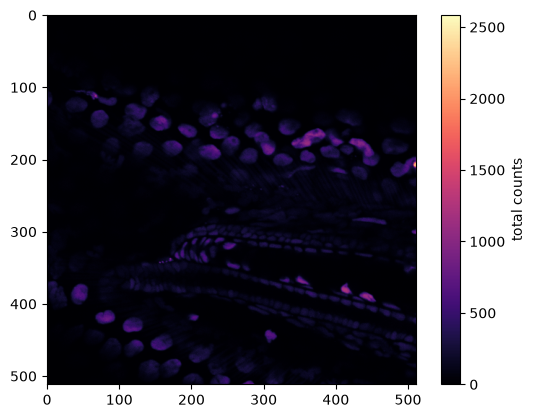

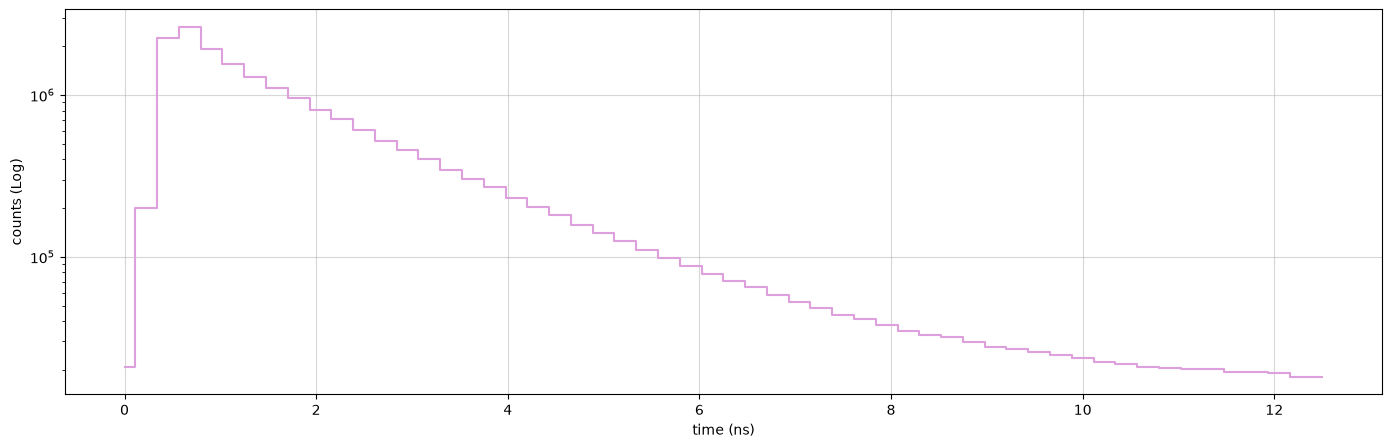

In [50]:
phplt.image_flattener(embryopic5)
phplt.global_image_plot(embryopic5)

In [51]:
image_flattener_plotly(img_red)
image_flattener_plotly(img_green)

# AYOOOO questo è interessante

In [52]:
# IRF: using calibration starch file. Starch has a tau of 0ns so it's ez
G_irf, S_irf = phf.extract_irf(starch_img, τ_fluor = 0.0, T_laser = T_laser)

# Phasor extraction with colored filters
G_red_raw, S_red_raw = phf.filter_image_phasors(img_red, threshold_pct = 0.05)
G_green_raw, S_green_raw = phf.filter_image_phasors(img_green, threshold_pct = 0.05)

# IRF deconvolution from calibration file
G_red_cal, S_red_cal = phf.phasor_deconv(G_red_raw, S_red_raw, G_irf, S_irf)
G_green_cal, S_green_cal = phf.phasor_deconv(G_green_raw, S_green_raw, G_irf, S_irf)



Max count: 1153 γ. Threshold: 58 γ.
Pixels over threshold: 67911/262144
Max count: 137 γ. Threshold: 7 γ.
Pixels over threshold: 74500/262144


Qui definisco le 2 maschere (le 2 regioni che mi aggradano)

In [53]:
#----ROI masks---------------------------------------------------------------------------
mask_size = 10

# Region 1 (190, 219)
x1_center, y1_center = 190, 219
mask_p1 = xr.zeros_like(embryopic5.isel(time = 0), dtype=bool)
mask_p1.loc[{
    "x": slice(x1_center - mask_size // 2, x1_center + mask_size // 2 - 1),
    "y": slice(y1_center - mask_size // 2, y1_center + mask_size // 2 - 1),
}] = True

# Region 2 (168, 287)
x2_center, y2_center = 168, 287
mask_p2 = xr.zeros_like(embryopic5.isel(time = 0), dtype=bool)
mask_p2.loc[{
    "x": slice(x2_center - mask_size // 2, x2_center + mask_size // 2 - 1),
    "y": slice(y2_center - mask_size // 2, y2_center + mask_size // 2 - 1),
}] = True
#---------------------------------------------------------------------------------------


applicazione filtro median su rosso, verde e totale (raw)

In [54]:
# 1- red and green data extraction (WITH median filter)
df_red = phf.phasors_from_region(img_red, roi_mask = full_mask, median_size = 3, threshold_pct = 0.05)
df_green = phf.phasors_from_region(img_green, roi_mask = full_mask, median_size = 3, threshold_pct = 0.1)

# 2- ROI 1 and 2 dataframe extraction, using p1 and p2 masks (WITH median filter)
df_p1 = phf.phasors_from_region(embryopic5, roi_mask = mask_p1, median_size = 3, threshold_pct = 0.05)
df_p2 = phf.phasors_from_region(embryopic5, roi_mask = mask_p2, median_size = 3, threshold_pct = 0.05)

# 3- separation of G and S values
G_red_raw, S_red_raw = df_red["G"].values, df_red["S"].values
G_green_raw, S_green_raw = df_green["G"].values, df_green["S"].values
G_p1_raw, S_p1_raw = df_p1["G"].values, df_p1["S"].values
G_p2_raw, S_p2_raw = df_p2["G"].values, df_p2["S"].values

# 4- IRF deconvolution
G_red_cal, S_red_cal = phf.phasor_deconv(G_red_raw, S_red_raw, G_irf, S_irf)
G_green_cal, S_green_cal = phf.phasor_deconv(G_green_raw, S_green_raw, G_irf, S_irf)
G_p1_cal, S_p1_cal = phf.phasor_deconv(G_p1_raw, S_p1_raw, G_irf, S_irf)
G_p2_cal, S_p2_cal = phf.phasor_deconv(G_p2_raw, S_p2_raw, G_irf, S_irf)

# 5- RED and GREEN MEAN CALCULATION
A = (float(np.nanmean(G_red_cal)), float(np.nanmean(S_red_cal)))
B = (float(np.nanmean(G_green_cal)), float(np.nanmean(S_green_cal)))

# NB: nanmean protects mean from empty pixels (NEED TO CHECK THE DIFFERENCE)

# ------------------------------------------------------------------
print(f" Red: G = {A[0]:.3f}, S = {A[1]:.3f}")
print(f" Green: G = {B[0]:.3f}, S = {B[1]:.3f}")

 Red: G = 0.632, S = 0.457
 Green: G = 0.965, S = 0.052


<h3> Confronto tra regione 1 e 2

In [55]:
# # POINTS COORDS
# p1_x, p1_y = 342, 217
# p2_x, p2_y = 168, 287

# # flattens without plotting (bc i need to add circles over chosen points)
# emb_flat = embryopic5.sum(axis=0) if embryopic5.ndim == 3 else embryopic5
# red_flat = img_red.sum(axis=0) if img_red.ndim == 3 else img_red
# green_flat = img_green.sum(axis=0) if img_green.ndim == 3 else img_green

# def plot_custom_style(image_data, title, points, colors):
    
#     fig, ax = plt.subplots(figsize=(7, 6))
#     im = ax.imshow(image_data, cmap='magma')
    
#     # CIRCLES
#     for (x, y), color in zip(points, colors):
#         ax.plot(x, y, marker='o', color=color, fillstyle='none', 
#                 markersize=20, markeredgewidth=2)
        
#     cbar = fig.colorbar(im, ax=ax)
#     cbar.set_label('total counts')
    
#     ax.set_title(title)
#     plt.tight_layout()
#     plt.show()

# # total
# plot_custom_style(
#     emb_flat, 
#     "Embryo Totale", 
#     [(p1_x, p1_y), (p2_x, p2_y)], 
#     ['cyan', 'lime']  # Colori vivaci per contrastare lo sfondo scuro
# )

# # red filter
# plot_custom_style(
#     red_flat, 
#     "Filtro Rosso", 
#     [(p1_x, p1_y)], 
#     ['cyan']
# )

# # green filter
# plot_custom_style(
#     green_flat, 
#     "Filtro Verde", 
#     [(p2_x, p2_y)], 
#     ['lime']
# )

In [56]:
# fractions for every pixel (ROI 1)
fraction_red_p1, fraction_green_p1 = phf.extract_fractions(
    P = (G_p1_cal, S_p1_cal),
    A = A,
    B = B
)

# fractions for every pixel (ROI 2)
fraction_red_p2, fraction_green_p2 = phf.extract_fractions(
    P = (G_p2_cal, S_p2_cal),
    A = A,
    B = B
)

# setting up dataframes
df_p1["Fraction_Red"] = fraction_red_p1
df_p1["Fraction_Green"] = fraction_green_p1

df_p2["Fraction_Red"] = fraction_red_p2
df_p2["Fraction_Green"] = fraction_green_p2

2 plot separati: uno con nuvola raw, nuvola deconvoluta e IRF per vedere dove si spostano i dati una volta deconvoluti; l'altro con verde rosso  e deconvoluta totale (obv anche verde e rosso sono state deconvolute nella cella prima di questa)

### Scelta fisica dell'incertezza


1. FILTRO ROSSO: easy, ho usato il metodo vecchio (deviazione standard campionaria), perché la SEM è troppo piccola a quanto pare anche perché i pixel vengono correlati dal filtro median

2. FILTRO VERDE: più problematico, ha una forma ellittica, quindi probabilmente è un mix di 2(+?) specie diverse, suppongo 2. Faccio matrice di covarianza e diagonalizzo, di seguito si spiegano i risultati

autovettori: direzione
- v1: direzione di massima varianza, retta gialla x intenderci

autovalori: ampiezza (quantificazione segnale-rumore)
- sqrt(lambda1) -> dev standard lungo la retta gialla = direz di mixing
- sqrt(lambda2)-> dev standard ortogonale (quantifica il rumore)

In [57]:
# RED AND GREEN STATS ------------------------------------------------------------------
(P1_mean, P1_covariance, P1_std, P1_pca_values, P1_pca_vectors, P1_n) = cloud_statistics(G_p1_cal, S_p1_cal)
(P2_mean, P2_covariance, P2_std, P2_pca_values, P2_pca_vectors, P2_n) = cloud_statistics(G_p2_cal, S_p2_cal)
(A, red_covariance, red_std, red_pca_values, red_pca_vectors, red_n) = cloud_statistics(G_red_cal, S_red_cal)
(B, green_covariance, green_std, green_pca_values, green_pca_vectors, green_n) = cloud_statistics(G_green_cal, S_green_cal)

# joining S and G stats in a single 2d variable
std_red_G, std_red_S = red_std
std_green_G, std_green_S = green_std
err_p1_G, err_p1_S = P1_std
err_p2_G, err_p2_S = P2_std
err_red_G, err_red_S = red_std
err_green_G, err_green_S = green_std

# Stampiamo i semiassi principali PCA (sqrt(lambda_1) = mixing, sqrt(lambda_2) = rumore)
print(f"Red   PCA axes: sigma_par = {np.sqrt(red_pca_values[0]):.5f}, sigma_perp = {np.sqrt(red_pca_values[1]):.5f}")
print(f"Green PCA axes: sigma_par = {np.sqrt(green_pca_values[0]):.5f}, sigma_perp = {np.sqrt(green_pca_values[1]):.5f}")
print(f"ROI 1 PCA axes: sigma_par = {np.sqrt(P1_pca_values[0]):.5f}, sigma_perp = {np.sqrt(P1_pca_values[1]):.5f}")
print(f"ROI 2 PCA axes: sigma_par = {np.sqrt(P2_pca_values[0]):.5f}, sigma_perp = {np.sqrt(P2_pca_values[1]):.5f}")


Red   PCA axes: sigma_par = 0.01785, sigma_perp = 0.01144
Green PCA axes: sigma_par = 0.07585, sigma_perp = 0.01523
ROI 1 PCA axes: sigma_par = 0.01964, sigma_perp = 0.00500
ROI 2 PCA axes: sigma_par = 0.01257, sigma_perp = 0.00723


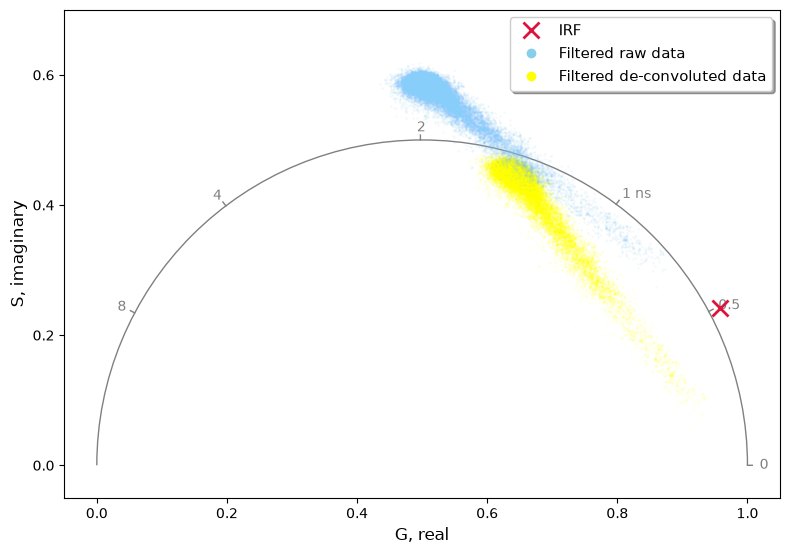

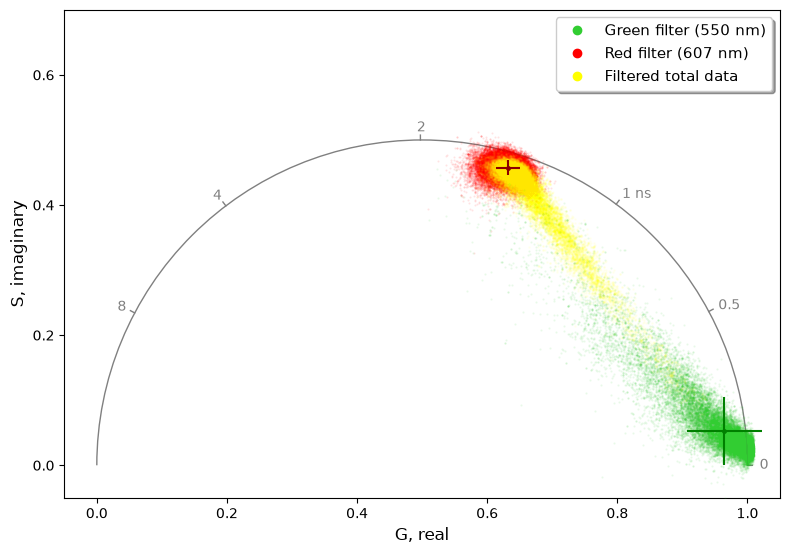

In [58]:
red_mc_covariance = np.diag(red_std ** 2)  # forces covariance to zero (will try without this)

points_plot1 = [
    {
        'G': G_emb_raw, 'S': S_emb_raw, 'color': 'lightskyblue',
        'marker': '.', 'markersize': 2, 'alpha': 0.05, 'linestyle': 'None', 'zorder': 6
    },
    # {
    #     'G': float(np.nanmean(G_emb_raw)), 'S': float(np.nanmean(S_emb_raw)),
    #     'label': 'Mean filtered raw', 'color': 'darkcyan',
    #     'marker': '.', 'markersize': 5, 'linestyle': 'None', 'zorder': 9
    # },
    {
        'G': G_emb_cal, 'S': S_emb_cal, 'color': 'yellow',
        'marker': '.', 'markersize': 2, 'alpha': 0.05, 'linestyle': 'None', 'zorder': 5
    },
    #{
    #     'G': float(np.nanmean(G_emb_cal)), 'S': float(np.nanmean(S_emb_cal)),
    #     'label': 'Mean filtered clean', 'color': 'darkgoldenrod',
    #     'marker': '.', 'markersize': 5, 'linestyle': 'None', 'zorder': 9
    # },
    {
        'G': G_irf, 'S': S_irf,
        'label': 'IRF', 'color': 'crimson',
        'marker': 'x', 'markersize': 12, 'markeredgewidth': 2, 'linestyle': 'None', 'zorder': 7
    },

    # DUMMY POINT(S) FOR LEGEND LEGIBILITY
    {                                       
        'G': [np.nan], 'S': [np.nan],
        'label': 'Filtered raw data', 'color': 'skyblue',
        'marker': '.', 'markersize': 12, 'alpha': 1.0, 'linestyle': 'None'
    },
    {
        'G': [np.nan], 'S': [np.nan],
        'label': 'Filtered de-convoluted data', 'color': 'yellow',
        'marker': '.', 'markersize': 12, 'alpha': 1.0, 'linestyle': 'None'
    },
]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_plot1)


points_plot2 = [
    {
        'G': G_emb_cal, 'S': S_emb_cal, 'color': 'yellow',
        'marker': '.', 'markersize': 2, 'alpha': 0.04, 'linestyle': 'None', 'zorder': 8
    },
    # {
    #     'G': float(np.nanmean(G_emb_cal)), 'S': float(np.nanmean(S_emb_cal)),
    #     'label': 'Mean filtered clean', 'color': 'darkgoldenrod',
    #     'marker': '.', 'markersize': 5, 'linestyle': 'None', 'zorder': 9
    # },
    {
        'G': G_red_cal, 'S': S_red_cal,
        'color': 'red', 'marker': '.', 'markersize': 1, 'alpha': 0.1, 'linestyle': 'None', 'zorder': 6
    },
    {
        'G': G_green_cal, 'S': S_green_cal,
        'color': 'limegreen', 'marker': '.', 'markersize': 1, 'alpha': 0.1, 'linestyle': 'None', 'zorder': 6
    },
    {
        'G': A[0], 'S': A[1],
        'xerr': std_red_G, 'yerr': std_red_S, 'color': 'darkred',
        'marker': '.', 'markersize': 5, 'linestyle': 'None', 'zorder': 8
    },
    {
        'G': B[0], 'S': B[1],
        'xerr': std_green_G, 'yerr': std_green_S, 'color': 'green',
        'marker': '.', 'markersize': 5, 'linestyle': 'None', 'zorder': 8
    },

    # DUMMY POINT(S) FOR LEGEND LEGIBILITY
    {                                       
        'G': [np.nan], 'S': [np.nan],
        'label': 'Green filter (550 nm)', 'color': 'limegreen',
        'marker': '.', 'markersize': 12, 'alpha': 1.0, 'linestyle': 'None'
    },
    {
        'G': [np.nan], 'S': [np.nan],
        'label': 'Red filter (607 nm)', 'color': 'red',
        'marker': '.', 'markersize': 12, 'alpha': 1.0, 'linestyle': 'None'
    },
        {
        'G': [np.nan], 'S': [np.nan],
        'label': 'Filtered total data', 'color': 'yellow',
        'marker': '.', 'markersize': 12, 'alpha': 1.0, 'linestyle': 'None'
    }
]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_plot2)

<h3> Confronto tra concentrazione in due punti diversi

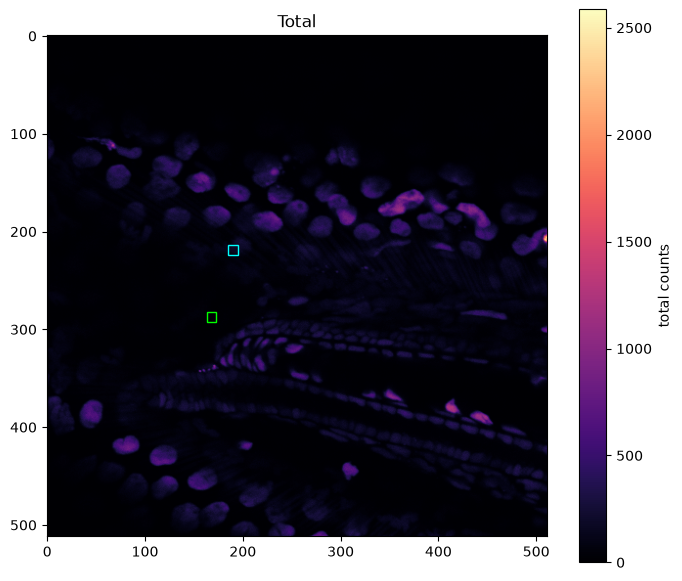

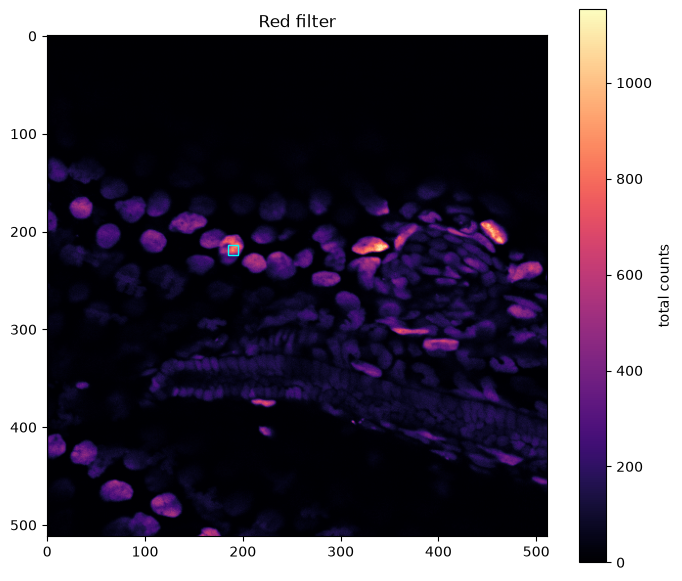

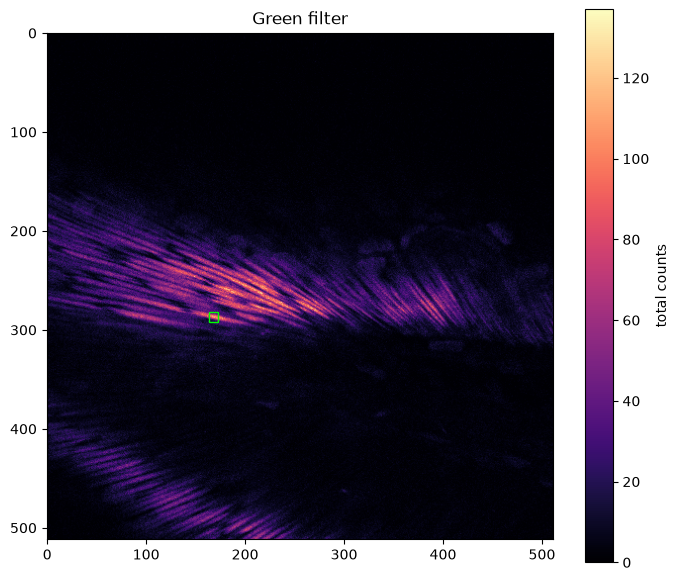

In [59]:
# flattens
emb_flat = embryopic5.sum(axis=0) if embryopic5.ndim == 3 else embryopic5
red_flat = img_red.sum(axis=0) if img_red.ndim == 3 else img_red
green_flat = img_green.sum(axis=0) if img_green.ndim == 3 else img_green

#PLOTTING------------------------------------------------------ 
def plot_custom_style(image_data, title, points, colors, square_width=15):
    
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(image_data, cmap='magma')
    
    # SQUARES
    for (x, y), color in zip(points, colors):

        rect = patches.Rectangle(
            (x - square_width / 2, y - square_width / 2), 
            square_width, square_width,
            linewidth=1, 
            edgecolor=color, 
            facecolor='none'
        )
        ax.add_patch(rect)
        
    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label('total counts')
    
    ax.set_title(title)
    plt.tight_layout()
    
    # plt.savefig(f"{title.replace(' ', '_')}.svg", format='svg', bbox_inches='tight')
    plt.show()

# total
plot_custom_style(
    emb_flat, 
    "Total", 
    [(x1_center, y1_center), (x2_center, y2_center)], 
    ['cyan', 'lime'],
    square_width=mask_size
)

# red filter
plot_custom_style(
    red_flat, 
    "Red filter", 
    [(x1_center, y1_center)], 
    ['cyan'],
    square_width=mask_size
)

# green filter
plot_custom_style(
    green_flat, 
    "Green filter", 
    [(x2_center, y2_center)], 
    ['lime'],
    square_width=mask_size
)

# Monte Carlo method for uncertainty 

<h3> Procedimento per il calcolo del rapporto tra concentrazioni relative di fluorofori (metodo Monte Carlo)

1. Definizione delle pdf delle variabili in ingresso: supponiamo siano gaussiane quindi estraiamo media e stddev dalla nuvola (mix clean, red clean e green clean)
2. Generazione dei campione: np.random.default_rng().normal crea array di 10k valori casuali secondo una distrib normale con sigma e mu determinate al pto 1. Gli array contengono 10k simulazioni di fasori possibili per il fasore medio interessato. Il processo viene eseguito 1x green, 1x red, 1x campione
3. Quando chiamo projection length passo, per ogni interazione, un elemento rosso, uno verde, e un campione. Calcolo le frazioni corrispondenti e salvo. Ripeto per tutta la lungh degli array
4. Faccio le statistiche (deviaz standard e media) per ottenere l'incertezza


Il metodo utilizzato viene descritto in:
1. JCGM 100:2008. Evaluation of measurement data — Guide to the expression of uncertainty in measurement. -> questo lo cito quando spiego perché non uso la propagazione standard degli errori. Vedere cose evidenziate sul pdf
2. JCGM 101:2008. Evaluation of measurement data — Supplement 1 to the "Guide to the expression of uncertainty in measurement" — Propagation of distributions using a Monte Carlo method. -> questo lo cito per il procedimento monte carlo

In [60]:
#  mean phasors for the 2 ROIs
P1_mean = (np.nanmean(G_p1_cal), np.nanmean(S_p1_cal))
P2_mean = (np.nanmean(G_p2_cal), np.nanmean(S_p2_cal))

# red and green fraction on mean phasors of 2 ROI areas
f_red_p1, f_green_p1 = phf.extract_fractions(P = P1_mean, A = A, B = B)
f_red_p2, f_green_p2 = phf.extract_fractions(P = P2_mean, A = A, B = B)

In [61]:
# Setting up the simulation ----------------------------------------------------
n_sim = 10_000
rng = np.random.default_rng()

# SIMULATING n_sim data, given error and mean, for each cloud -------------------
red_sim = rng.multivariate_normal(A, red_mc_covariance, size=n_sim)     # RED: noise induced cloud, ''no covariance'' (forced to 0)
green_sim = rng.multivariate_normal(B, green_covariance, size=n_sim)        # GREEN: creates an ellipse of (simulated) data!
p1_sim = rng.multivariate_normal(P1_mean, P1_covariance, size = n_sim)      # ROI1: same as green, calculated with raw data from roi1
p2_sim = rng.multivariate_normal(P2_mean, P2_covariance, size = n_sim)      # ROI2: same as green, calculated with raw data from roi2

# filling 2 arrays (for each roi) with 0s for later ----------------------------------
f1_p1_sims, f2_p1_sims = np.empty(n_sim), np.empty(n_sim)
f1_p2_sims, f2_p2_sims = np.empty(n_sim), np.empty(n_sim)

# ERROR PROPAGATION ----------------------------------------------------------------
for i in range(n_sim):
    f1_p1_sims[i], f2_p1_sims[i] = phf.extract_fractions(
        P = p1_sim[i], A = red_sim[i], B = green_sim[i]
    )
    f1_p2_sims[i], f2_p2_sims[i] = phf.extract_fractions(
        P = p2_sim[i], A = red_sim[i], B = green_sim[i]
    )

# FINAL ERROR -> std of monte carlo sims
f1_p1_err, f2_p1_err = np.std(f1_p1_sims, ddof = 1), np.std(f2_p1_sims, ddof = 1)
f1_p2_err, f2_p2_err = np.std(f1_p2_sims, ddof = 1), np.std(f2_p2_sims, ddof = 1)

# delta_red = f_red_p1 - f_red_p2           # useless
# delta_red_err = np.std(f1_p1_sims - f1_p2_sims, ddof=1)

print("\nMix ratios - region 1 (190, 219)")
print(f"  f1 (Red)   = {f_red_p1:.6f} +/- {f1_p1_err:.6f}")
print(f"  f2 (Green) = {f_green_p1:.6f} +/- {f2_p1_err:.6f}")
print("\nMix ratios - region 2 (168, 287)")
print(f"  f1 (Red)   = {f_red_p2:.6f} +/- {f1_p2_err:.6f}")
print(f"  f2 (Green) = {f_green_p2:.6f} +/- {f2_p2_err:.6f}")
# print(f"\nDelta f Red (ROI 1 - ROI 2) = {delta_red:.6f} +/- {delta_red_err:.6f}")



Mix ratios - region 1 (190, 219)
  f1 (Red)   = 0.931822 +/- 0.047936
  f2 (Green) = 0.068178 +/- 0.047936

Mix ratios - region 2 (168, 287)
  f1 (Red)   = 0.970895 +/- 0.037157
  f2 (Green) = 0.029105 +/- 0.037157


<h3> Final plots of regions 1 and 2

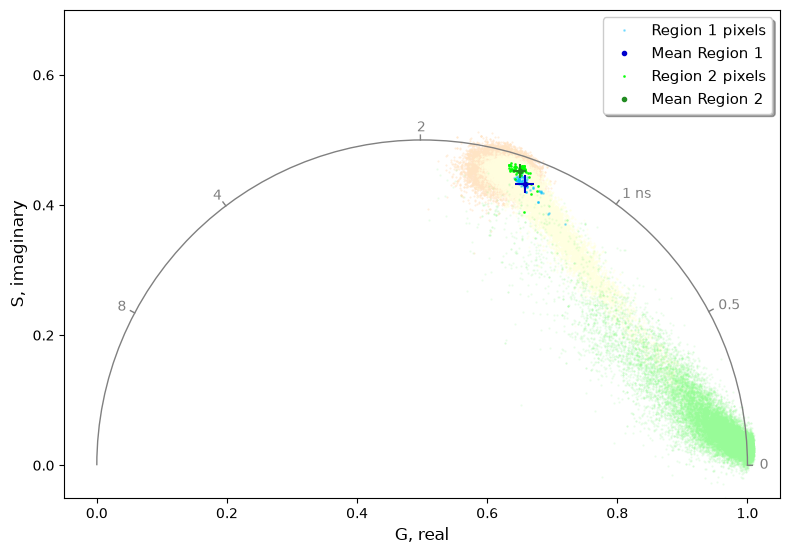

In [62]:
points_plot_regions = [
    # --- REGION 1 ---------------------------
    {
        'G': G_p1_cal, 'S': S_p1_cal,
        'label': 'Region 1 pixels', 'color': 'deepskyblue', # Ciano/azzurro brillante
        'marker': '.', 'markersize': 2, 'alpha': 0.35, 'linestyle': 'None', 'zorder': 5
    },
    {
        'G': float(np.nanmean(G_p1_cal)), 'S': float(np.nanmean(S_p1_cal)),
        'xerr': err_p1_G, 'yerr': err_p1_S,
        'label': 'Mean Region 1', 'color': 'mediumblue', # Blu scuro per staccare dalla nube ciano
        'marker': 'o', 'markersize': 3, 'linestyle': 'None', 'zorder': 9
    },

    # --- REGION 2 --------------------------------
    {
        'G': G_p2_cal, 'S': S_p2_cal,
        'label': 'Region 2 pixels', 'color': 'lime', 
        'marker': '.', 'markersize': 2, 'alpha': 0.8, 'linestyle': 'None', 'zorder': 6
    },
    {
        'G': float(np.nanmean(G_p2_cal)), 'S': float(np.nanmean(S_p2_cal)),
        'xerr': err_p2_G, 'yerr': err_p2_S,
        'label': 'Mean Region 2', 'color': 'forestgreen',
        'marker': 'o', 'markersize': 3, 'linestyle': 'None', 'zorder': 9
    },

    # --- GREEN AND RED------------------------------------------------  # they make the plot even more confusing
    # {
    #     'G': A[0], 'S': A[1],
    #     'xerr': err_red_G, 'yerr': err_red_S,
    #     'label': 'Red filter (607 nm)', 'color': 'red', 'alpha': 0.1,
    #     'marker': 'D', 'markersize': 3, 'linestyle': 'None', 'zorder': 2
    # },
    # {
    #     'G': B[0], 'S': B[1],
    #     'xerr': err_green_G, 'yerr': err_green_S,
    #     'label': 'Green filter (550 nm)', 'color': 'limegreen', 'alpha': 0.3,
    #     'marker': 'D', 'markersize': 3, 'linestyle': 'None', 'zorder': 10
    # },
    # --- BACKGROUND CLOUDS (No legend) ----------------------

    {
        'G': G_red_cal, 'S': S_red_cal,
        'color': 'bisque', 'marker': '.', 'markersize': 1, 'alpha': 0.6, 'linestyle': 'None', 'zorder': 1
    },
    {
        'G': G_emb_cal, 'S': S_emb_cal, 'color': 'lightyellow',
        'marker': '.', 'markersize': 1, 'alpha': 0.5, 'linestyle': 'None', 'zorder': 1
    },
    {
        'G': G_green_cal, 'S': S_green_cal,
        'color': 'palegreen', 'marker': '.', 'markersize': 1, 'alpha': 0.2, 'linestyle': 'None', 'zorder': 1
    }

]

phplt.universal_phasor_plot(T_laser = T_laser, points = points_plot_regions)

# penso di aver passato 2 ore a cercare di rendere questo grafico leggibile quindi CHE NESSUNO TOCCHI I COLORI


# Diagnostica PCA delle nuvole
(+ valori finali con incertezze)

In [63]:
def print_pca_summary(name, mean, covariance, eigenvalues, eigenvectors, n):  # questa funzione è un capolavoro 

    major_axis, minor_axis = np.sqrt(np.maximum(eigenvalues, 0.0))
    direction = eigenvectors[:, 0]
    angle_deg = np.degrees(np.arctan2(direction[1], direction[0]))

    print(f"\n{name} (N = {n})")
    print(f"  mean = (G: {mean[0]:.6f}, S: {mean[1]:.6f})")
    print("  covariance =")
    print(covariance)
    print(f"  PCA: maj axis = {major_axis:.6f}, min axis = {minor_axis:.6f}")
    print(f"  maj axis directiona = ({direction[0]:.6f}, {direction[1]:.6f}), angle = {angle_deg:.2f} deg")

print("PCA: cloud spread over trajectory vs noise")

for summary in (
    ("ROI 1", P1_mean, P1_covariance, P1_pca_values, P1_pca_vectors, P1_n),
    ("ROI 2", P2_mean, P2_covariance, P2_pca_values, P2_pca_vectors, P2_n),
    ("Red mean phasor", A, red_covariance, red_pca_values, red_pca_vectors, red_n),
    ("Green mean phasor", B, green_covariance, green_pca_values, green_pca_vectors, green_n),
):
    print_pca_summary(*summary)


PCA: cloud spread over trajectory vs noise

ROI 1 (N = 81)
  mean = (G: 0.657760, S: 0.432262)
  covariance =
[[ 0.00021413 -0.00018011]
 [-0.00018011  0.00019659]]
  PCA: maj axis = 0.019639, min axis = 0.005004
  maj axis directiona = (-0.724102, 0.689693), angle = 136.39 deg

ROI 2 (N = 81)
  mean = (G: 0.650050, S: 0.452431)
  covariance =
[[ 9.39650816e-05 -5.16456708e-05]
 [-5.16456708e-05  1.16258105e-04]]
  PCA: maj axis = 0.012568, min axis = 0.007230
  maj axis directiona = (-0.628105, 0.778129), angle = 128.91 deg

Red mean phasor (N = 67911)
  mean = (G: 0.631969, S: 0.457320)
  covariance =
[[ 3.14639940e-04 -2.74477083e-05]
 [-2.74477083e-05  1.35042655e-04]]
  PCA: maj axis = 0.017853, min axis = 0.011443
  maj axis directiona = (-0.989021, 0.147777), angle = 171.50 deg

Green mean phasor (N = 41387)
  mean = (G: 0.964620, S: 0.052307)
  covariance =
[[ 0.00326442 -0.00274731]
 [-0.00274731  0.00272107]]
  PCA: maj axis = 0.075852, min axis = 0.015233
  maj axis directio

In [64]:
print("Fraction of green emitting and red emitting molecules in ROI 1 and 2")
print("\n")
print(f"ROI 1: red = {f_red_p1:.6f} +/- {f1_p1_err:.6f}, green = {f_green_p1:.6f} +/- {f2_p1_err:.6f}")
print(f"ROI 2: red = {f_red_p2:.6f} +/- {f1_p2_err:.6f}, green = {f_green_p2:.6f} +/- {f2_p2_err:.6f}")
# print("\n")
# print(f"Delta f Red (ROI 1 - ROI 2) = {delta_red:.6f} +/- {delta_red_err:.6f}")


Fraction of green emitting and red emitting molecules in ROI 1 and 2


ROI 1: red = 0.931822 +/- 0.047936, green = 0.068178 +/- 0.047936
ROI 2: red = 0.970895 +/- 0.037157, green = 0.029105 +/- 0.037157
